# Лекция 6 [17-25-2]. Основные распределения: как они выглядят и как ими прогнозировать

Демонстрационный ноутбук к лекции. Здесь ничего не нужно дописывать: запускайте ячейки по порядку, меняйте параметры и смотрите на графики.

1. **Дискретные распределения**: равномерное, биномиальное, Пуассона, геометрическое, гипергеометрическое. Как форма зависит от параметров, проверка $E(X)$ и $\mathrm{Var}(X)$ симуляцией.
2. **Непрерывные распределения**: равномерное, показательное, нормальное, Вейбулла. Интенсивность отказов и «отсутствие памяти».
3. **Кейс «Цена жилья»**: модель машинного обучения предсказывает не одно число, а параметры логнормального распределения цены.
4. **Кейс «Отток клиентов»**: модель предсказывает параметры распределения Вейбулла для времени, которое клиент пробудет с компанией.

### Как открыть ноутбук в Google Colab

1. Скачайте файл `.ipynb` на свой компьютер.
2. Откройте [colab.research.google.com](https://colab.research.google.com) и войдите в свой Google-аккаунт.
3. Выберите «Файл → Загрузить блокнот» (File → Upload notebook), перейдите на вкладку «Загрузить» и выберите скачанный файл. Можно просто перетащить файл в окно.
4. Ноутбук сохранится на вашем Google Диске в папке «Colab Notebooks». В следующий раз открывайте его оттуда.
5. «Среда выполнения → Выполнить все» (Runtime → Run all) запускает все ячейки, `Shift+Enter` — одну.

Ячейки с ползунками (`interact`) работают в Colab и Jupyter: двигайте ползунок, и график перерисуется. Для кейсов 3 и 4 нужен интернет: данные загружаются с GitHub.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize, special

rng = np.random.default_rng(2026)
plt.rcParams["figure.figsize"] = (9, 4.2)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
BLUE, GRAY, DARK = "#1F6BFF", "#9CA3AF", "#111827"

try:
    from ipywidgets import interact, IntSlider, FloatSlider
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print("ipywidgets не найден: ползунки не появятся, статические графики работают")

### Шпаргалка по `scipy.stats`

| Метод | Что считает |
|---|---|
| `pmf(k)` | $P(X=k)$ для дискретной величины |
| `pdf(x)` | плотность $f(x)$ для непрерывной |
| `cdf(x)` | $P(X\le x)$. На лекции $F(x)=P(X<x)$; для непрерывных величин это одно и то же |
| `sf(x)` | $P(X>x)$, «хвост» справа |
| `ppf(q)` | квантиль уровня $q$ |
| `mean()`, `var()`, `std()` | $E(X)$, $\mathrm{Var}(X)$, $\sigma(X)$ |
| `rvs(size=n)` | $n$ случайных значений |

Названия распределений и параметров в `scipy`:

| Распределение | На лекции | В `scipy.stats` |
|---|---|---|
| Равномерное дискретное на $\{a,\dots,b\}$ | $U\{a,b\}$ | `randint(a, b + 1)` |
| Биномиальное | $\mathrm{Bin}(n,p)$ | `binom(n, p)` |
| Пуассона | $\mathrm{Pois}(\lambda)$ | `poisson(lam)` |
| Геометрическое (номер первого успеха) | $\mathrm{Geom}(p)$ | `geom(p)` |
| Гипергеометрическое: $N$ деталей, $M$ бракованных, берём $n$ | $\mathrm{HG}(N,M,n)$ | `hypergeom(N, M, n)` |
| Равномерное на $[a;b]$ | $U(a,b)$ | `uniform(loc=a, scale=b - a)` |
| Показательное | $\mathrm{Exp}(\lambda)$ | `expon(scale=1 / lam)` |
| Нормальное | $N(a,\sigma^2)$ | `norm(loc=a, scale=sigma)` |
| Вейбулла | $\mathrm{Weib}(k,\lambda)$ | `weibull_min(k, scale=lam)` |
| Логнормальное | $\mathrm{LogN}(\mu,\sigma^2)$ | `lognorm(s=sigma, scale=np.exp(mu))` |

Обратите внимание: у `scipy` масштаб показательного закона — это $1/\lambda$, а не $\lambda$.

---
## 1. Дискретные распределения

Сначала функция, которая рисует ряд распределения столбиками и отмечает $E(X)$ и интервал $E(X)\pm\sigma$.

In [2]:
def plot_pmf(dist, ks, ax=None, title="", color=BLUE):
    ax = ax or plt.gca()
    ax.bar(ks, dist.pmf(ks), color=color, width=0.8)
    m, s = dist.mean(), dist.std()
    ax.axvline(m, color=DARK, ls="--", lw=1.2)
    ax.axvspan(m - s, m + s, color=GRAY, alpha=0.18)
    ax.set_title(f"{title}\nE = {m:.2f}, Var = {dist.var():.2f}", fontsize=10)
    ax.set_xlabel("k"); ax.set_ylabel("P(X = k)")

### 1.1. Галерея: как параметры меняют форму

Пунктир — $E(X)$, серая полоса — $E(X)\pm\sigma$.

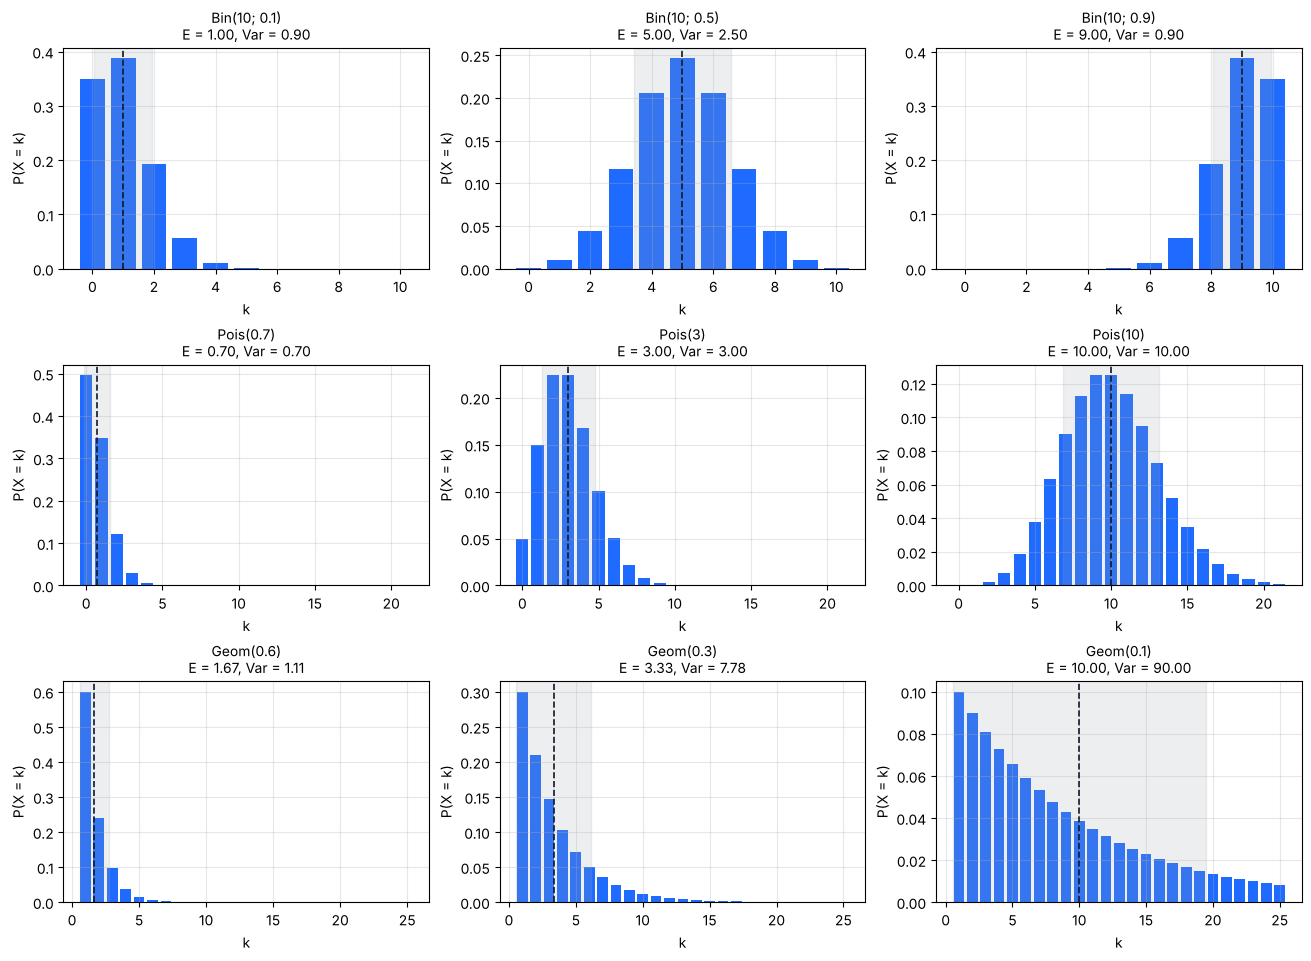

In [3]:
fig, axs = plt.subplots(3, 3, figsize=(13, 9.5), constrained_layout=True)
for ax, p in zip(axs[0], [0.1, 0.5, 0.9]):
    plot_pmf(stats.binom(10, p), np.arange(0, 11), ax, f"Bin(10; {p})")
for ax, lam in zip(axs[1], [0.7, 3, 10]):
    plot_pmf(stats.poisson(lam), np.arange(0, 22), ax, f"Pois({lam})")
for ax, p in zip(axs[2], [0.6, 0.3, 0.1]):
    plot_pmf(stats.geom(p), np.arange(1, 26), ax, f"Geom({p})")
plt.show()

Что видно:

* у биномиального при $p=0{,}5$ ряд симметричен, при малом $p$ «прижат» к нулю, при большом — к $n$;
* у закона Пуассона с ростом $\lambda$ центр сдвигается вправо, а разброс растёт вместе с ним: $\mathrm{Var}(X)=E(X)=\lambda$;
* у геометрического самое вероятное значение всегда $k=1$, а чем меньше $p$, тем длиннее хвост.

### 1.2. Ползунки

Подвигайте параметры. Ячейка работает в Colab и Jupyter.

In [ ]:
if HAS_WIDGETS:
    @interact(n=IntSlider(10, 1, 60), p=FloatSlider(value=0.3, min=0.01, max=0.99, step=0.01))
    def binom_demo(n, p):
        plot_pmf(stats.binom(n, p), np.arange(0, n + 1), title=f"Bin({n}; {p:.2f})")
        plt.show()

In [ ]:
if HAS_WIDGETS:
    @interact(lam=FloatSlider(value=3, min=0.2, max=25, step=0.1))
    def poisson_demo(lam):
        plot_pmf(stats.poisson(lam), np.arange(0, int(lam + 5 * np.sqrt(lam)) + 4), title=f"Pois({lam:.1f})")
        plt.show()

In [ ]:
if HAS_WIDGETS:
    @interact(N=IntSlider(20, 5, 200), M=IntSlider(5, 0, 200), n=IntSlider(4, 1, 200))
    def hypergeom_demo(N, M, n):
        M, n = min(M, N), min(n, N)
        hg, bn = stats.hypergeom(N, M, n), stats.binom(n, M / N)
        ks = np.arange(0, n + 1)
        plt.bar(ks - 0.2, hg.pmf(ks), width=0.4, color=BLUE, label=f"HG: без возвращения, Var = {hg.var():.2f}")
        plt.bar(ks + 0.2, bn.pmf(ks), width=0.4, color=GRAY, label=f"Bin: с возвращением, Var = {bn.var():.2f}")
        plt.xlabel("число бракованных в выборке"); plt.legend(); plt.show()

### 1.3. Пуассон как предел биномиального

Число испытаний $n$ растёт, а $p=\lambda/n$ уменьшается так, что $np=3$ остаётся постоянным. Биномиальный ряд всё точнее совпадает с рядом Пуассона.

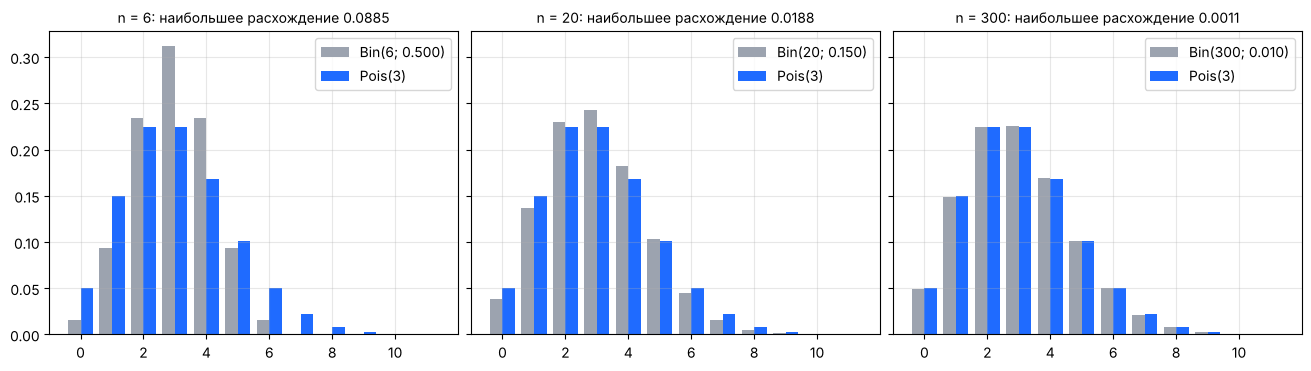

In [7]:
lam, ks = 3, np.arange(0, 12)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, constrained_layout=True)
for ax, n in zip(axs, [6, 20, 300]):
    b = stats.binom(n, lam / n)
    ax.bar(ks - 0.2, b.pmf(ks), width=0.4, color=GRAY, label=f"Bin({n}; {lam/n:.3f})")
    ax.bar(ks + 0.2, stats.poisson(lam).pmf(ks), width=0.4, color=BLUE, label="Pois(3)")
    gap = np.abs(b.pmf(np.arange(0, 60)) - stats.poisson(lam).pmf(np.arange(0, 60))).max()
    ax.set_title(f"n = {n}: наибольшее расхождение {gap:.4f}", fontsize=10); ax.legend()
plt.show()

### 1.4. Гипергеометрическое: выборка без возвращения

Партия из $N$ деталей, среди них $M$ бракованных, берём $n$ деталей **без возвращения**. Если бы мы возвращали деталь обратно, число бракованных было бы биномиальным с $p=M/N$. Среднее у обоих законов одно и то же, $nM/N$, а дисперсия у гипергеометрического меньше в $\frac{N-n}{N-1}$ раз: каждая вынутая деталь даёт информацию об оставшихся.

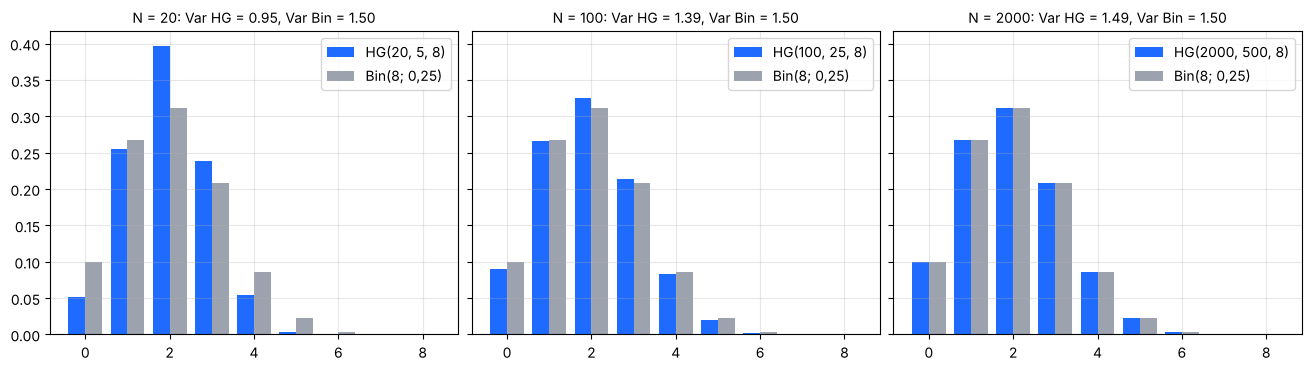

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, constrained_layout=True)
for ax, N in zip(axs, [20, 100, 2000]):
    M, n = N // 4, 8
    hg, bn = stats.hypergeom(N, M, n), stats.binom(n, M / N)
    ks = np.arange(0, n + 1)
    ax.bar(ks - 0.2, hg.pmf(ks), width=0.4, color=BLUE, label=f"HG({N}, {M}, {n})")
    ax.bar(ks + 0.2, bn.pmf(ks), width=0.4, color=GRAY, label=f"Bin({n}; 0,25)")
    ax.set_title(f"N = {N}: Var HG = {hg.var():.2f}, Var Bin = {bn.var():.2f}", fontsize=10); ax.legend()
plt.show()

При партии из 2000 деталей законы почти не отличаются: если партия намного больше выборки, гипергеометрическое можно заменять биномиальным.

### 1.5. Проверяем формулы $E(X)$ и $\mathrm{Var}(X)$ симуляцией

Для каждого закона генерируем 200 000 значений и сравниваем выборочные среднее и дисперсию с формулами из лекции.

In [9]:
N_SIM = 200_000
discrete = {
    "U{1..6} (кубик)":  (stats.randint(1, 7),          (1 + 6) / 2,  (6**2 - 1) / 12),
    "Bin(10; 0,1)":     (stats.binom(10, 0.1),          10 * 0.1,     10 * 0.1 * 0.9),
    "Pois(3)":          (stats.poisson(3),              3,            3),
    "Geom(0,3)":        (stats.geom(0.3),               1 / 0.3,      0.7 / 0.3**2),
    "HG(20, 5, 4)":     (stats.hypergeom(20, 5, 4),     4 * 5 / 20,   4 * (5/20) * (15/20) * (20 - 4) / (20 - 1)),
}
rows = []
for name, (dist, e_formula, var_formula) in discrete.items():
    x = dist.rvs(size=N_SIM, random_state=rng)
    rows.append([name, e_formula, x.mean(), var_formula, x.var()])
pd.DataFrame(rows, columns=["закон", "E по формуле", "среднее выборки", "Var по формуле", "дисперсия выборки"]).round(3)

,закон,E по формуле,среднее выборки,Var по формуле,дисперсия выборки
0,U{1..6} (кубик),3.500,3.495,2.917,2.916
1,"Bin(10; 0,1)",1.000,0.996,0.900,0.899
2,Pois(3),3.000,3.002,3.000,3.009
3,"Geom(0,3)",3.333,3.338,7.778,7.760
4,"HG(20, 5, 4)",1.000,1.002,0.632,0.632


---
## 2. Непрерывные распределения

### 2.1. Галерея плотностей

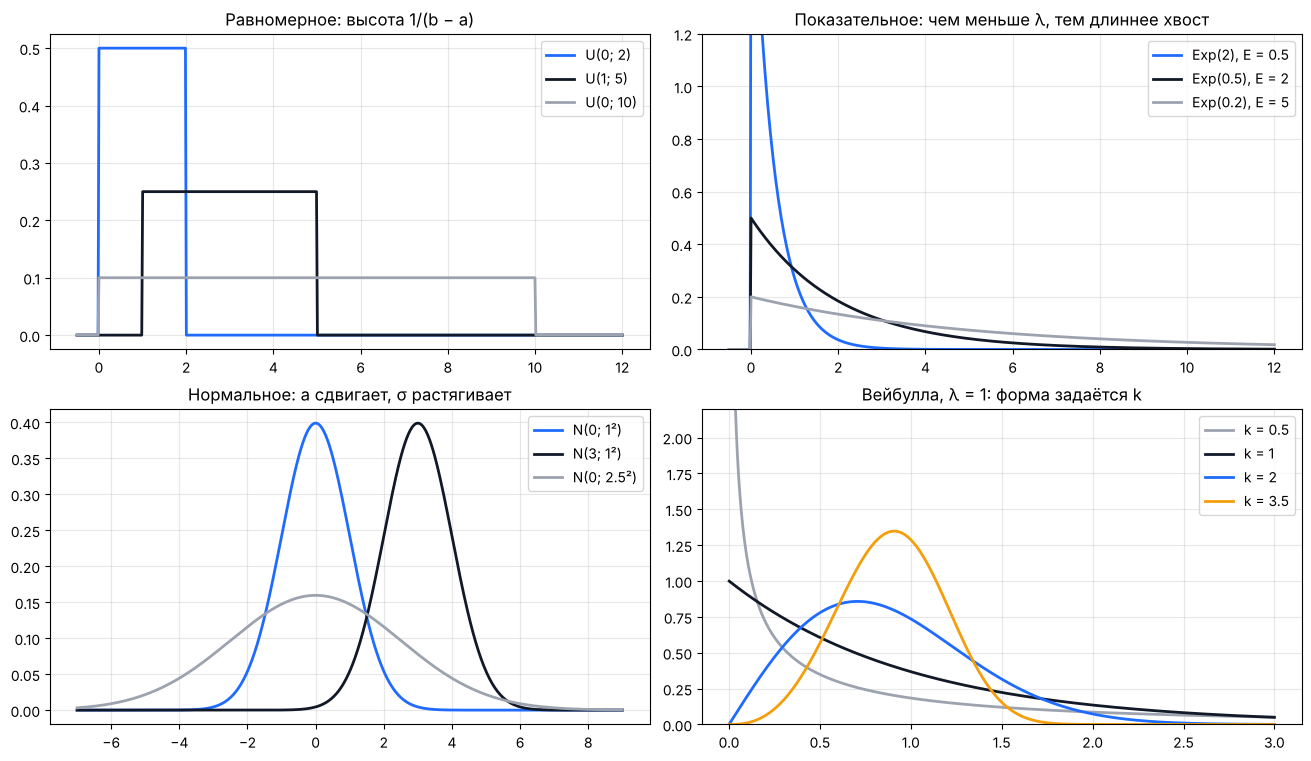

In [10]:
x = np.linspace(-0.5, 12, 600)
fig, axs = plt.subplots(2, 2, figsize=(13, 7.5), constrained_layout=True)

ax = axs[0, 0]
for (a, b), c in zip([(0, 2), (1, 5), (0, 10)], [BLUE, DARK, GRAY]):
    ax.plot(x, stats.uniform(a, b - a).pdf(x), color=c, lw=2, label=f"U({a}; {b})")
ax.set_title("Равномерное: высота 1/(b − a)"); ax.legend()

ax = axs[0, 1]
for lam, c in zip([2, 0.5, 0.2], [BLUE, DARK, GRAY]):
    ax.plot(x, stats.expon(scale=1 / lam).pdf(x), color=c, lw=2, label=f"Exp({lam}), E = {1/lam:g}")
ax.set_ylim(0, 1.2); ax.set_title("Показательное: чем меньше λ, тем длиннее хвост"); ax.legend()

ax = axs[1, 0]
z = np.linspace(-7, 9, 600)
for (a, s), c in zip([(0, 1), (3, 1), (0, 2.5)], [BLUE, DARK, GRAY]):
    ax.plot(z, stats.norm(a, s).pdf(z), color=c, lw=2, label=f"N({a}; {s}²)")
ax.set_title("Нормальное: a сдвигает, σ растягивает"); ax.legend()

ax = axs[1, 1]
t = np.linspace(0.001, 3, 600)
for k, c in zip([0.5, 1, 2, 3.5], [GRAY, DARK, BLUE, "#F59E0B"]):
    ax.plot(t, stats.weibull_min(k, scale=1).pdf(t), color=c, lw=2, label=f"k = {k}")
ax.set_ylim(0, 2.2); ax.set_title("Вейбулла, λ = 1: форма задаётся k"); ax.legend()
plt.show()

In [ ]:
if HAS_WIDGETS:
    @interact(k=FloatSlider(value=1.5, min=0.3, max=5, step=0.1), lam=FloatSlider(value=1, min=0.2, max=3, step=0.1))
    def weibull_demo(k, lam):
        d = stats.weibull_min(k, scale=lam)
        t = np.linspace(0.001, 4, 500)
        fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
        axs[0].plot(t, d.pdf(t), color=BLUE, lw=2); axs[0].axvline(d.mean(), color=DARK, ls="--")
        axs[0].set_title(f"Плотность. E = {d.mean():.3f}, σ = {d.std():.3f}")
        axs[1].plot(t, d.pdf(t) / d.sf(t), color=BLUE, lw=2); axs[1].set_ylim(0, 6)
        axs[1].set_title("Интенсивность отказов h(t) = f(t) / P(T > t)")
        plt.show()

### 2.2. Интенсивность отказов: почему одного показательного закона мало

Интенсивность отказов $h(t)=\dfrac{f(t)}{P(T>t)}$ показывает, насколько вероятен отказ «прямо сейчас» для прибора, который дожил до момента $t$.

* $k<1$: $h(t)$ убывает. Отказывают в основном «новички» с дефектом (приработка). Кто пережил начало, служит долго.
* $k=1$: $h(t)=\lambda$ постоянна. Это показательный закон, прибор «не стареет».
* $k>1$: $h(t)$ растёт. Износ: чем старше прибор, тем вероятнее отказ.

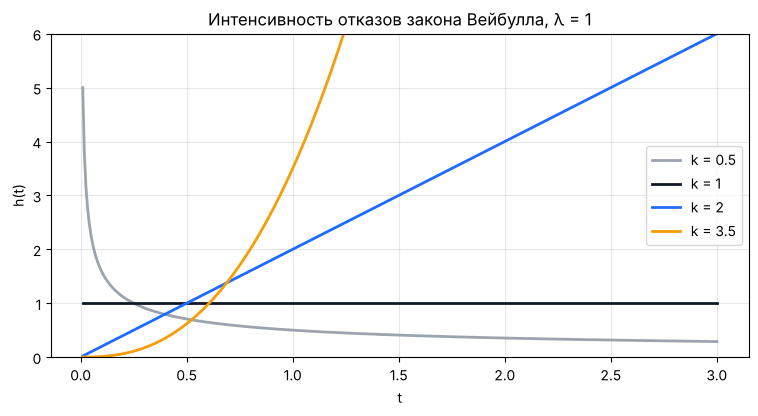

In [12]:
t = np.linspace(0.01, 3, 400)
for k, c in zip([0.5, 1, 2, 3.5], [GRAY, DARK, BLUE, "#F59E0B"]):
    d = stats.weibull_min(k, scale=1)
    plt.plot(t, d.pdf(t) / d.sf(t), color=c, lw=2, label=f"k = {k}")
plt.ylim(0, 6); plt.xlabel("t"); plt.ylabel("h(t)"); plt.legend(); plt.title("Интенсивность отказов закона Вейбулла, λ = 1")
plt.show()

### 2.3. Отсутствие памяти: симуляция

Прибор уже проработал $s=1$ (тыс. часов). Какова вероятность, что он проработает ещё хотя бы $t=1$? Сравниваем с вероятностью, что **новый** прибор проработает хотя бы $t=1$. У показательного закона эти вероятности совпадают, у Вейбулла с $k>1$ старый прибор хуже нового.

In [13]:
s_, t_ = 1.0, 1.0
for name, d in [("Exp(1)", stats.expon()), ("Weib(k = 2, λ = 1,5)", stats.weibull_min(2, scale=1.5))]:
    T = d.rvs(size=500_000, random_state=rng)
    p_new = np.mean(T > t_)
    p_old = np.mean(T[T > s_] > s_ + t_)
    print(f"{name:22s}  новый: P(T > {t_:g}) = {p_new:.3f}   проработавший {s_:g}: P(T > {s_ + t_:g} | T > {s_:g}) = {p_old:.3f}")

Exp(1)                  новый: P(T > 1) = 0.368   проработавший 1: P(T > 2 | T > 1) = 0.368
Weib(k = 2, λ = 1,5)    новый: P(T > 1) = 0.639   проработавший 1: P(T > 2 | T > 1) = 0.264


### 2.4. Правило трёх сигм и формулы для непрерывных законов

In [14]:
d = stats.norm(0, 1)
for m in [1, 2, 3]:
    print(f"P(|X − a| < {m}σ) = {d.cdf(m) - d.cdf(-m):.4f}")

continuous = {
    "U(0; 10)":           (stats.uniform(0, 10),            5,                       100 / 12),
    "Exp(0,5)":           (stats.expon(scale=2),            2,                       4),
    "N(20; 0,1²)":        (stats.norm(20, 0.1),             20,                      0.01),
    "Weib(k=1,5; λ=1000)": (stats.weibull_min(1.5, scale=1000),
                           1000 * special.gamma(1 + 1 / 1.5),
                           1000**2 * (special.gamma(1 + 2 / 1.5) - special.gamma(1 + 1 / 1.5) ** 2)),
}
rows = []
for name, (dist, e_formula, var_formula) in continuous.items():
    x = dist.rvs(size=N_SIM, random_state=rng)
    rows.append([name, e_formula, x.mean(), var_formula, x.var()])
pd.DataFrame(rows, columns=["закон", "E по формуле", "среднее выборки", "Var по формуле", "дисперсия выборки"]).round(4)

P(|X − a| < 1σ) = 0.6827
P(|X − a| < 2σ) = 0.9545
P(|X − a| < 3σ) = 0.9973


,закон,E по формуле,среднее выборки,Var по формуле,дисперсия выборки
0,U(0; 10),5.0000,4.9914,8.3333,8.3160
1,"Exp(0,5)",2.0000,2.0014,4.0000,4.0002
2,"N(20; 0,1²)",20.0000,20.0000,0.0100,0.0100
3,"Weib(k=1,5; λ=1000)",902.7453,901.3067,375690.2848,379199.3689


У закона Вейбулла в формулах стоит гамма-функция $\Gamma$. Это обобщение факториала: $\Gamma(m+1)=m!$ для целых $m$. В Python она есть в `scipy.special.gamma`.

In [15]:
print([special.gamma(m + 1) for m in range(5)], "= 0!, 1!, 2!, 3!, 4!")
print("Γ(1 + 1/1,5) =", round(special.gamma(1 + 1 / 1.5), 4))

[np.float64(1.0), np.float64(1.0), np.float64(2.0), np.float64(6.0), np.float64(24.0)] = 0!, 1!, 2!, 3!, 4!
Γ(1 + 1/1,5) = 0.9027


---
## 3. Кейс «Цена жилья»: модель предсказывает распределение

### Зачем

Обычная регрессия отвечает одним числом: «дом стоит 210 тыс. $». Покупателю, банку или оценщику полезнее другое: в каком диапазоне цена окажется с вероятностью 80 %, и какова вероятность, что она выше 300 тыс. Для этого модель должна предсказывать **параметры распределения** цены, а не одно число.

### Данные

Перепись Калифорнии 1990 года (набор из книги А. Жерона «Hands-On Machine Learning»): 20 640 кварталов. Для каждого квартала есть медианная стоимость дома `median_house_value`, медианный доход жителей, возраст домов, число комнат, население, удалённость от океана. В наборе нет цен выше 500 000 $: всё, что дороже, записано как 500 001. Эти кварталы (около 5 %) уберём, чтобы не усложнять пример.

In [16]:
URL_HOUSING = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
housing = pd.read_csv(URL_HOUSING)
print("всего кварталов:", len(housing), " с ценой 500 001:", (housing.median_house_value > 500_000).sum())
housing = housing[housing.median_house_value < 500_000].dropna().reset_index(drop=True)
housing["price"] = housing.median_house_value / 1000          # тыс. $
housing.head()

всего кварталов: 20640  с ценой 500 001: 965


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,price
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,452.6
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,358.5
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,352.1
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,341.3
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,342.2


### 3.1. Какое распределение у цены?

Цена положительна, у неё длинный правый хвост: дешёвых кварталов много, дорогих мало, но они бывают очень дорогими. Нормальный закон для такой величины плох: он симметричен и допускает отрицательные цены.

Подходит **логнормальное распределение**: величина $Y$ логнормальна, если $\ln Y$ распределён нормально, $\ln Y\sim N(\mu,\sigma^2)$. Тогда

$$\text{медиана}=e^{\mu},\qquad E(Y)=e^{\mu+\sigma^2/2},\qquad \mathrm{Var}(Y)=\left(e^{\sigma^2}-1\right)e^{2\mu+\sigma^2}.$$

Логнормальный закон естественно возникает, когда на величину действует много **умножающих** факторов: цена = базовая цена × коэффициент района × коэффициент состояния × …. Логарифм превращает произведение в сумму, а сумма многих факторов по ЦПТ близка к нормальной.

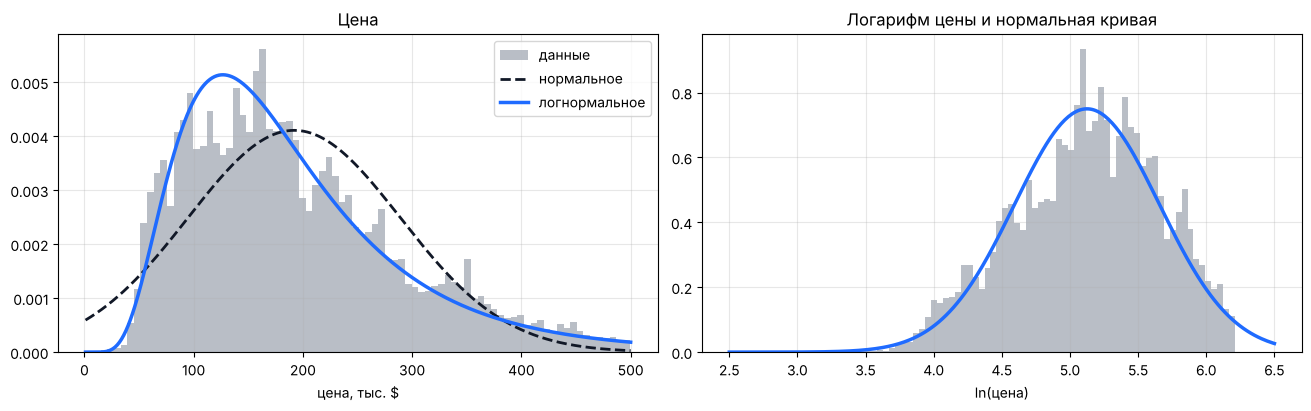

μ = 5.125, σ = 0.532;  медиана e^μ = 168 тыс. $, E(Y) = e^(μ+σ²/2) = 194 тыс. $, среднее выборки = 192 тыс. $


In [17]:
y = housing.price.values
mu_hat, sigma_hat = np.log(y).mean(), np.log(y).std()
grid = np.linspace(1, 500, 500)

fig, axs = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
axs[0].hist(y, bins=80, density=True, color=GRAY, alpha=0.7, label="данные")
axs[0].plot(grid, stats.norm(y.mean(), y.std()).pdf(grid), color=DARK, ls="--", lw=2, label="нормальное")
axs[0].plot(grid, stats.lognorm(s=sigma_hat, scale=np.exp(mu_hat)).pdf(grid), color=BLUE, lw=2.5, label="логнормальное")
axs[0].set_xlabel("цена, тыс. $"); axs[0].legend(); axs[0].set_title("Цена")
axs[1].hist(np.log(y), bins=80, density=True, color=GRAY, alpha=0.7)
lg = np.linspace(2.5, 6.5, 300)
axs[1].plot(lg, stats.norm(mu_hat, sigma_hat).pdf(lg), color=BLUE, lw=2.5)
axs[1].set_xlabel("ln(цена)"); axs[1].set_title("Логарифм цены и нормальная кривая")
plt.show()
print(f"μ = {mu_hat:.3f}, σ = {sigma_hat:.3f};  медиана e^μ = {np.exp(mu_hat):.0f} тыс. $, "
      f"E(Y) = e^(μ+σ²/2) = {np.exp(mu_hat + sigma_hat**2 / 2):.0f} тыс. $, среднее выборки = {y.mean():.0f} тыс. $")

Одно распределение на все кварталы — это модель «без признаков»: для любого квартала она выдаёт одну и ту же широкую кривую. Но квартал с высоким доходом жителей у океана и квартал в глубине штата стоят по-разному. Пусть параметры зависят от признаков квартала $x$:

$$\ln Y \mid x \sim N\big(\mu(x),\ \sigma(x)^2\big).$$

$\mu(x)$ отвечает за «центр» цены, $\sigma(x)$ — за неопределённость: где-то цену можно предсказать точно, где-то нет.

### 3.2. Признаки и разбиение на обучение и проверку

In [18]:
from sklearn.model_selection import train_test_split

X = pd.DataFrame({
    "ln_income":   np.log(housing.median_income),                  # доход, десятки тыс. $
    "age_10":      housing.housing_median_age / 10,                # возраст домов, десятилетия
    "ln_rooms":    np.log(housing.total_rooms / housing.households),
    "ln_people":   np.log(housing.population / housing.households),
})
X = pd.concat([X, pd.get_dummies(housing.ocean_proximity, prefix="ocean", drop_first=True).astype(float)], axis=1)
ln_y = np.log(housing.price.values)

idx_train, idx_test = train_test_split(np.arange(len(X)), test_size=0.25, random_state=0)
print("обучение:", len(idx_train), " проверка:", len(idx_test))
X.head()

обучение: 14586  проверка: 4862


,ln_income,age_10,ln_rooms,ln_people,ocean_INLAND,ocean_ISLAND,ocean_NEAR BAY,ocean_NEAR OCEAN
0,2.119287,4.1,1.943640,0.938270,0.0,0.0,1.0,0.0
1,2.116424,2.1,1.830682,0.746613,0.0,0.0,1.0,0.0
2,1.982022,5.2,2.114825,1.030426,0.0,0.0,1.0,0.0
3,1.730434,5.2,1.760845,0.935287,0.0,0.0,1.0,0.0
4,1.347086,5.2,1.837665,0.779998,0.0,0.0,1.0,0.0


### 3.3. Как обучить модель, которая выдаёт распределение: правдоподобие

Для каждого квартала модель выдаёт $\mu(x_i)$ и $\sigma(x_i)$, то есть плотность $f(y\mid x_i)$. Хорошая модель даёт **большую плотность в той точке, где оказалась настоящая цена** $y_i$. Поэтому минимизируем средний минус логарифм плотности (*negative log-likelihood*, NLL):

$$\mathrm{NLL}=-\frac1n\sum_{i=1}^n \ln f\big(y_i\mid \mu(x_i),\sigma(x_i)\big).$$

Если $\sigma$ одна на всех, минимизация NLL для нормального закона совпадает с минимизацией среднего квадрата ошибки (MSE). Привычная регрессия — частный случай.

**Модель A.** Без признаков: $\mu$ и $\sigma$ одни на все кварталы.

**Модель B.** Линейная: $\mu(x)=w_0+w_1x_1+\dots$, $\ln\sigma(x)=v_0+v_1x_1+\dots$. Логарифм нужен, чтобы $\sigma$ всегда была положительной. Веса $w$ и $v$ подбирает `scipy.optimize.minimize`.

In [19]:
def nll_lognormal(y, mu, sigma):
    # средний минус логарифм плотности логнормального закона в точках y
    return -np.mean(stats.lognorm(s=sigma, scale=np.exp(mu)).logpdf(y))

Xa = np.c_[np.ones(len(X)), X.values]               # столбец единиц — свободный член
p = Xa.shape[1]

def loss_B(theta, Xa, ln_y):
    mu, ln_sigma = Xa @ theta[:p], Xa @ theta[p:]
    return -np.mean(stats.norm.logpdf(ln_y, mu, np.exp(ln_sigma)))

theta0 = np.zeros(2 * p); theta0[0] = ln_y[idx_train].mean()
res = optimize.minimize(loss_B, theta0, args=(Xa[idx_train], ln_y[idx_train]), method="L-BFGS-B")
w, v = res.x[:p], res.x[p:]
pd.DataFrame({"вес в μ(x)": w, "вес в ln σ(x)": v}, index=["const"] + list(X.columns)).round(3)

,вес в μ(x),вес в ln σ(x)
const,4.777,-0.896
ln_income,0.740,-0.322
age_10,0.027,0.027
ln_rooms,-0.054,-0.073
ln_people,-0.376,0.033
ocean_INLAND,-0.429,0.209
ocean_ISLAND,0.693,-0.132
ocean_NEAR BAY,-0.021,0.147
ocean_NEAR OCEAN,0.012,0.218


Как читать веса. Вес `ln_income` в $\mu(x)$ около 0,74: если доход жителей вырастет на 10 %, медианная цена вырастет примерно на 7 %. Отрицательный вес `ln_income` в $\ln\sigma(x)$: в богатых кварталах цена предсказуемее. Отрицательный вес `ocean_INLAND` в $\mu(x)$ означает, что кварталы в глубине штата дешевле, а положительный вес в $\ln\sigma(x)$ — что там цена предсказуема хуже.

**Модель C.** Градиентный бустинг (`HistGradientBoostingRegressor` из `sklearn`) в два шага:

1. первая модель предсказывает $\mu(x)$ — центр $\ln Y$;
2. вторая модель предсказывает, насколько велика ошибка первой: обучаем её на $\ln(\text{остаток}^2)$, а затем переводим в $\sigma(x)$.

Остатки для второго шага берём «честные» (кросс-валидация), иначе первая модель на своих же данных ошибается слишком мало. Поправка $+1{,}27$ возникает так: если $\varepsilon\sim N(0,\sigma^2)$, то $E\ln\varepsilon^2=\ln\sigma^2-1{,}27$.

In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict

Xg = np.c_[X.values, housing.longitude.values, housing.latitude.values]   # бустингу добавим координаты
gb_mu = HistGradientBoostingRegressor(max_iter=300, random_state=0)
oof = cross_val_predict(gb_mu, Xg[idx_train], ln_y[idx_train], cv=5)       # «честные» прогнозы на обучении
gb_mu.fit(Xg[idx_train], ln_y[idx_train])
gb_sigma = HistGradientBoostingRegressor(max_iter=200, random_state=0)
gb_sigma.fit(Xg[idx_train], np.log((ln_y[idx_train] - oof) ** 2 + 1e-6))

def predict_C(rows):
    mu = gb_mu.predict(Xg[rows])
    sigma = np.exp((gb_sigma.predict(Xg[rows]) + 1.27) / 2)
    return mu, sigma

### 3.4. Сравнение моделей на проверочной выборке

* **NLL** — чем меньше, тем лучше модель описывает распределение цен;
* **ошибка медианы** — средняя относительная ошибка, если прогнозировать одним числом $e^{\mu(x)}$;
* **покрытие 80 % и 95 %** — в какой доле кварталов настоящая цена попала в предсказанный интервал. У честной модели должно быть около 80 % и 95 %;
* **ширина 80 %** — средняя ширина интервала. При одинаковом покрытии чем уже, тем полезнее.

In [21]:
y_test = housing.price.values[idx_test]
models = {
    "A: без признаков": (np.full(len(idx_test), ln_y[idx_train].mean()), np.full(len(idx_test), ln_y[idx_train].std())),
    "B: линейная":      (Xa[idx_test] @ w, np.exp(Xa[idx_test] @ v)),
    "C: бустинг":       predict_C(idx_test),
}
rows = []
for name, (mu, sigma) in models.items():
    d = stats.lognorm(s=sigma, scale=np.exp(mu))
    lo80, hi80 = d.ppf(0.10), d.ppf(0.90)
    lo95, hi95 = d.ppf(0.025), d.ppf(0.975)
    rows.append([name, nll_lognormal(y_test, mu, sigma),
                 np.mean(np.abs(np.exp(mu) - y_test) / y_test),
                 np.mean((y_test >= lo80) & (y_test <= hi80)), np.mean((y_test >= lo95) & (y_test <= hi95)),
                 np.mean(hi80 - lo80)])
compare = pd.DataFrame(rows, columns=["модель", "NLL", "ошибка медианы", "покрытие 80%", "покрытие 95%", "ширина 80%, тыс. $"])
compare.round(3)

,модель,NLL,ошибка медианы,покрытие 80%,покрытие 95%,"ширина 80%, тыс. $"
0,A: без признаков,5.925,0.489,0.774,0.959,246.294
1,B: линейная,5.374,0.251,0.821,0.950,140.980
2,C: бустинг,4.932,0.152,0.809,0.934,85.129


Все три модели «честные»: покрытие близко к заявленному. Но интервал модели без признаков огромный, он одинаков для всех кварталов и почти бесполезен. Модель C при том же покрытии даёт интервалы в несколько раз уже.

### 3.5. Прогноз для двух конкретных кварталов

Возьмём из проверочной выборки два квартала со схожей медианой прогноза, но разной уверенностью модели.

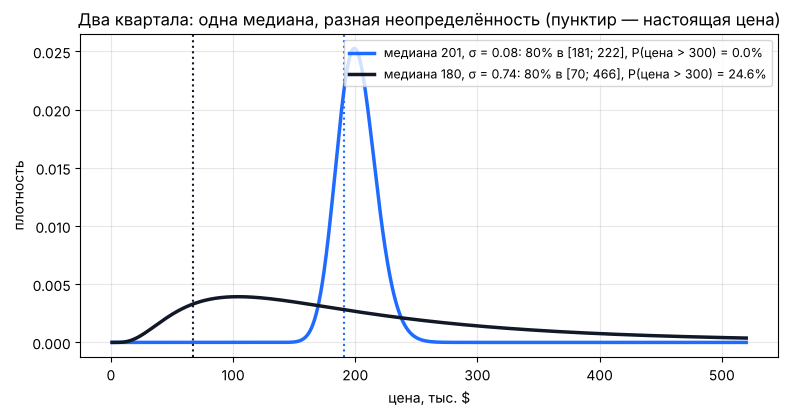

,median_income,housing_median_age,ocean_proximity,population,households,price
10603,4.5739,35.0,<1H OCEAN,1033.0,297.0,190.5
4411,7.5752,52.0,<1H OCEAN,55.0,7.0,67.5


In [22]:
mu_C, sigma_C = models["C: бустинг"]
med_C = np.exp(mu_C)
band = np.where((med_C > 180) & (med_C < 220))[0]
i_sure, i_unsure = band[np.argmin(sigma_C[band])], band[np.argmax(sigma_C[band])]

grid = np.linspace(1, 520, 800)
threshold = 300
for i, c in [(i_sure, BLUE), (i_unsure, DARK)]:
    d = stats.lognorm(s=sigma_C[i], scale=med_C[i])
    plt.plot(grid, d.pdf(grid), color=c, lw=2.5,
             label=f"медиана {med_C[i]:.0f}, σ = {sigma_C[i]:.2f}: 80% в [{d.ppf(.1):.0f}; {d.ppf(.9):.0f}], "
                   f"P(цена > {threshold}) = {d.sf(threshold):.1%}")
    plt.axvline(y_test[i], color=c, ls=":", lw=1.5)
plt.xlabel("цена, тыс. $"); plt.ylabel("плотность"); plt.legend(fontsize=9, loc="upper right")
plt.title("Два квартала: одна медиана, разная неопределённость (пунктир — настоящая цена)")
plt.show()
housing.iloc[idx_test[[i_sure, i_unsure]]][["median_income", "housing_median_age", "ocean_proximity", "population", "households", "price"]]

Точечный прогноз у кварталов почти одинаковый. Распределения разные: для первого модель уверена, для второго честно говорит, что цена может оказаться и 80, и 400 тыс. Посмотрите на таблицу: во втором квартале всего несколько домохозяйств, и «медианная цена» по нескольким домам сама по себе случайна. Модель выучила, что такие кварталы непредсказуемы. Именно это и нужно банку, который выдаёт ипотеку под залог, или оценщику, который решает, нужен ли выезд на место.

---
## 4. Кейс «Отток клиентов»: сколько клиент пробудет с компанией

### Зачем

Телеком-оператор хочет знать, когда клиент уйдёт. Точечный прогноз «уйдёт через 20 месяцев» мало полезен: важно, какова вероятность, что клиент останется хотя бы год, сколько месяцев он в среднем ещё заплатит и кого удерживать скидкой. Это вопросы о **распределении** времени жизни клиента $T$.

### Данные

Открытый набор IBM Telco Customer Churn: 7043 клиента. `tenure` — сколько месяцев клиент с компанией, `Churn` — ушёл ли он (Yes/No), а также тип договора, тариф интернета, способ оплаты и ежемесячный платёж.

In [23]:
URL_CHURN = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
churn = pd.read_csv(URL_CHURN)
churn = churn[churn.tenure > 0].reset_index(drop=True)     # 11 клиентов только подключились
T = churn.tenure.values.astype(float)                       # месяцы
event = (churn.Churn == "Yes").values.astype(float)         # 1 — ушёл, 0 — ещё с нами
print(f"клиентов: {len(churn)}, ушли: {event.mean():.1%}, наибольший срок: {T.max():.0f} мес.")
churn[["customerID", "tenure", "Churn", "Contract", "InternetService", "PaymentMethod", "MonthlyCharges"]].head()

клиентов: 7032, ушли: 26.6%, наибольший срок: 72 мес.


,customerID,tenure,Churn,Contract,InternetService,PaymentMethod,MonthlyCharges
0,7590-VHVEG,1,No,Month-to-month,DSL,Electronic check,29.85
1,5575-GNVDE,34,No,One year,DSL,Mailed check,56.95
2,3668-QPYBK,2,Yes,Month-to-month,DSL,Mailed check,53.85
3,7795-CFOCW,45,No,One year,DSL,Bank transfer (automatic),42.30
4,9237-HQITU,2,Yes,Month-to-month,Fiber optic,Electronic check,70.70


### 4.1. Цензурирование: самое важное в данных о времени

Для ушедшего клиента мы знаем время жизни $T$ точно. Для 73 % клиентов, которые ещё с нами, знаем только, что $T$ **не меньше** текущего срока. Такие наблюдения называются **цензурированными**.

Типичная ошибка — выбросить их или считать, что они «ушли сегодня». Тогда модель решит, что клиенты уходят гораздо быстрее, чем на самом деле. Правильно учитывать оба типа наблюдений в правдоподобии:

$$\ln L=\sum_{\text{ушли}}\ln f(t_i)\;+\;\sum_{\text{остались}}\ln P(T>t_i).$$

Для ушедших берём плотность в точке ухода, для оставшихся — вероятность прожить дольше текущего срока.

### 4.2. Эмпирическая кривая «дожития» (Каплан — Мейер)

Сначала посмотрим на данные без модели. Кривая Каплана — Мейера оценивает $S(t)=P(T>t)$ и правильно учитывает цензурирование: в каждый месяц делим число ушедших на число клиентов, которые были под наблюдением в этот месяц.

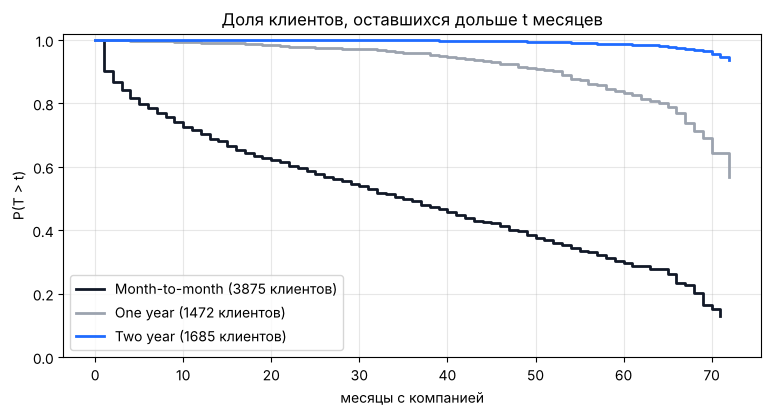

In [24]:
def kaplan_meier(t, e):
    times = np.unique(t[e == 1])
    s, surv = 1.0, []
    for u in times:
        at_risk = np.sum(t >= u)          # кто ещё под наблюдением в месяц u
        died = np.sum((t == u) & (e == 1))
        s *= 1 - died / at_risk
        surv.append(s)
    return np.r_[0, times], np.r_[1, surv]

for contract, c in [("Month-to-month", DARK), ("One year", GRAY), ("Two year", BLUE)]:
    m = (churn.Contract == contract).values
    tt, ss = kaplan_meier(T[m], event[m])
    plt.step(tt, ss, where="post", color=c, lw=2, label=f"{contract} ({m.sum()} клиентов)")
plt.ylim(0, 1.02); plt.xlabel("месяцы с компанией"); plt.ylabel("P(T > t)"); plt.legend()
plt.title("Доля клиентов, оставшихся дольше t месяцев")
plt.show()

### 4.3. Один закон Вейбулла на всех и цена ошибки с цензурированием

$S(t)=P(T>t)=e^{-(t/\lambda)^k}$, плотность $f(t)=\dfrac{k}{\lambda}\left(\dfrac{t}{\lambda}\right)^{k-1}e^{-(t/\lambda)^k}$. Параметры будем искать в виде $\lambda=e^{a}$, $k=e^{b}$, чтобы они были положительными.

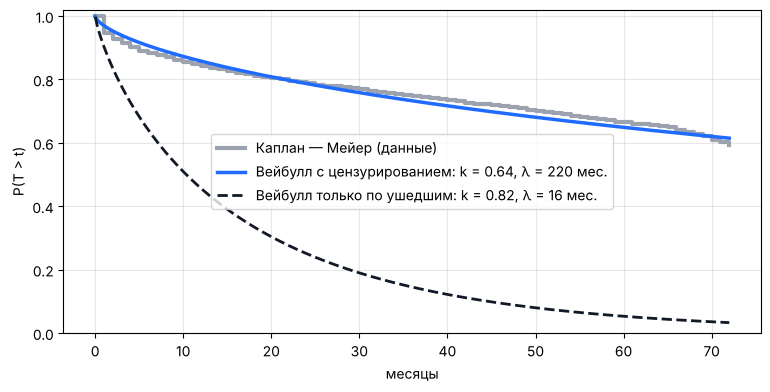

In [25]:
def weibull_loglik_terms(t, e, lam, k):
    z = t / lam
    log_S = -z**k
    log_f = np.log(k) - np.log(lam) + (k - 1) * np.log(z) + log_S
    return e * log_f + (1 - e) * log_S

def fit_weibull(t, e):
    loss = lambda th: -np.sum(weibull_loglik_terms(t, e, np.exp(th[0]), np.exp(th[1])))
    th = optimize.minimize(loss, [np.log(t.mean()), 0.0], method="L-BFGS-B").x
    return np.exp(th[0]), np.exp(th[1])

lam_ok, k_ok = fit_weibull(T, event)                                   # правильно: с цензурированием
lam_bad, k_bad = fit_weibull(T[event == 1], event[event == 1])         # ошибка: только ушедшие
tt, ss = kaplan_meier(T, event)
grid_t = np.linspace(0.01, 72, 300)
plt.step(tt, ss, where="post", color=GRAY, lw=3, label="Каплан — Мейер (данные)")
plt.plot(grid_t, stats.weibull_min(k_ok, scale=lam_ok).sf(grid_t), color=BLUE, lw=2.5,
         label=f"Вейбулл с цензурированием: k = {k_ok:.2f}, λ = {lam_ok:.0f} мес.")
plt.plot(grid_t, stats.weibull_min(k_bad, scale=lam_bad).sf(grid_t), color=DARK, ls="--", lw=2,
         label=f"Вейбулл только по ушедшим: k = {k_bad:.2f}, λ = {lam_bad:.0f} мес.")
plt.ylim(0, 1.02); plt.xlabel("месяцы"); plt.ylabel("P(T > t)"); plt.legend(); plt.show()

Модель «только по ушедшим» уверена, что почти все клиенты уходят за пару лет. Модель с цензурированием совпадает с данными.

Параметр формы $k<1$: интенсивность ухода убывает. Новые клиенты уходят чаще всего, а кто остался на год-два, становится лояльным. Это та же картина, что у приборов с «приработкой».

### 4.4. ML-модель: параметры Вейбулла зависят от клиента

Пусть оба параметра зависят от признаков клиента:

$$\ln\lambda(x)=w_0+w_1x_1+\dots,\qquad \ln k(x)=v_0+v_1\cdot[\text{договор на 1 год}]+v_2\cdot[\text{договор на 2 года}].$$

Масштаб $\lambda(x)$ зависит от всех признаков, форма $k(x)$ — только от типа договора. Множитель $e^{w_j}$ показывает, во сколько раз меняется масштаб $\lambda$ при изменении признака. Если бы форма была одна на всех, это была бы классическая модель *Weibull AFT* (accelerated failure time): признаки растягивают или сжимают шкалу времени.

In [26]:
F = pd.DataFrame({
    "договор на 1 год":     churn.Contract == "One year",
    "договор на 2 года":    churn.Contract == "Two year",
    "оптоволокно":          churn.InternetService == "Fiber optic",
    "без интернета":        churn.InternetService == "No",
    "электронный чек":      churn.PaymentMethod == "Electronic check",
    "есть партнёр":         churn.Partner == "Yes",
    "платёж, +10 $":        (churn.MonthlyCharges - 65) / 10,
}).astype(float)
Fa = np.c_[np.ones(len(F)), F.values]
tr, te = train_test_split(np.arange(len(F)), test_size=0.25, random_state=0)

Ga = Fa[:, :3]                               # для k(x): константа и два столбца договора
p_lam = Fa.shape[1]

def params(th, Fa, Ga):
    return np.exp(Fa @ th[:p_lam]), np.exp(Ga @ th[p_lam:])     # λ(x), k(x)

def loss_aft(th, Fa, Ga, t, e):
    lam, k = params(th, Fa, Ga)
    return -np.sum(weibull_loglik_terms(t, e, lam, k))

th0 = np.r_[np.log(lam_ok), np.zeros(F.shape[1]), np.log(k_ok), 0, 0]
th = optimize.minimize(loss_aft, th0, args=(Fa[tr], Ga[tr], T[tr], event[tr]), method="L-BFGS-B").x
for name, g in [("помесячно", [1, 0, 0]), ("договор на 1 год", [1, 1, 0]), ("договор на 2 года", [1, 0, 1])]:
    print(f"k для «{name}» = {np.exp(np.array(g) @ th[p_lam:]):.2f}")
pd.DataFrame({"вес w": th[:p_lam], "множитель e^w": np.exp(th[:p_lam])}, index=["const"] + list(F.columns)).round(2)

k для «помесячно» = 0.82
k для «договор на 1 год» = 2.06
k для «договор на 2 года» = 3.31


,вес w,множитель e^w
const,4.29,73.22
договор на 1 год,0.77,2.17
договор на 2 года,0.88,2.42
оптоволокно,-1.02,0.36
без интернета,0.92,2.50
электронный чек,-0.44,0.64
есть партнёр,0.42,1.53
"платёж, +10 $",0.20,1.23


Договор увеличивает масштаб времени жизни, оптоволокно и оплата электронным чеком сокращают его. Это согласуется с кривыми Каплана — Мейера выше.

Интереснее параметр формы. У клиентов без договора $k<1$: опаснее всего первые месяцы. У клиентов с договором $k>1$: интенсивность ухода растёт со временем, клиенты уходят ближе к окончанию договора. Одна и та же модель описывает и «приработку», и «износ».

### 4.5. Проверка на новых клиентах

Для клиентов из проверочной выборки усредняем предсказанные кривые $S(t\mid x)$ внутри каждого типа договора и сравниваем с кривой Каплана — Мейера по тем же клиентам.

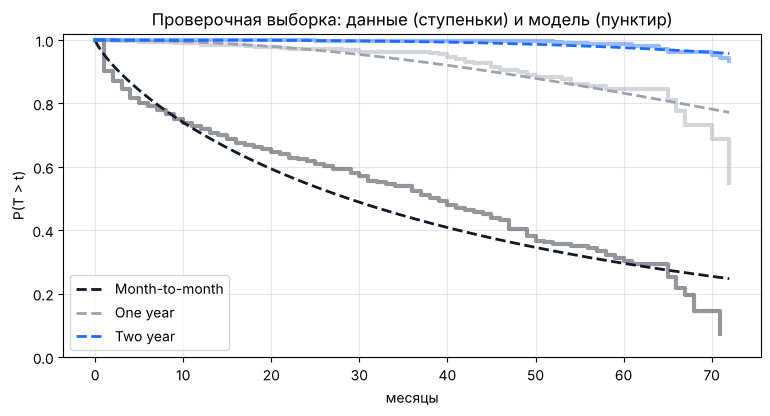

In [27]:
lam_te, k_te = params(th, Fa[te], Ga[te])
for contract, c in [("Month-to-month", DARK), ("One year", GRAY), ("Two year", BLUE)]:
    m = (churn.Contract.values[te] == contract)
    tt, ss = kaplan_meier(T[te][m], event[te][m])
    plt.step(tt, ss, where="post", color=c, lw=3, alpha=0.45)
    pred = np.mean([stats.weibull_min(k, scale=l).sf(grid_t) for l, k in zip(lam_te[m], k_te[m])], axis=0)
    plt.plot(grid_t, pred, color=c, lw=2, ls="--", label=contract)
plt.ylim(0, 1.02); plt.xlabel("месяцы"); plt.ylabel("P(T > t)")
plt.title("Проверочная выборка: данные (ступеньки) и модель (пунктир)"); plt.legend(); plt.show()

### 4.6. Прогноз для конкретных клиентов

Для каждого нового клиента модель выдаёт целое распределение. Из него получаем ответы на бизнес-вопросы:

* $P(T>12)$ — вероятность, что клиент останется хотя бы год;
* $P(T>36)$ — вероятность, что клиент останется хотя бы три года;
* $\int_0^{24}S(t)\,dt$ — ожидаемое число оплаченных месяцев за ближайшие два года. Умножив на платёж, получаем ожидаемую выручку.

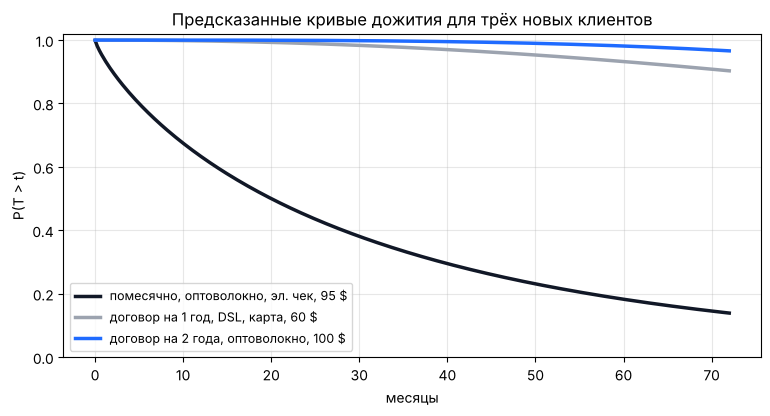

,клиент,P(T > 12),P(T > 36),мес. из 24,"выручка за 24 мес., $"
0,"помесячно, оптоволокно, эл. чек, 95 $",0.63,0.33,15.80,1501.35
1,"договор на 1 год, DSL, карта, 60 $",1.00,0.98,23.92,1434.98
2,"договор на 2 года, оптоволокно, 100 $",1.00,1.00,23.99,2399.49


In [28]:
from scipy import integrate

clients = pd.DataFrame([
    {"кто": "помесячно, оптоволокно, эл. чек, 95 $", "договор на 1 год": 0, "договор на 2 года": 0, "оптоволокно": 1,
     "без интернета": 0, "электронный чек": 1, "есть партнёр": 0, "платёж, +10 $": (95 - 65) / 10, "платёж": 95},
    {"кто": "договор на 1 год, DSL, карта, 60 $", "договор на 1 год": 1, "договор на 2 года": 0, "оптоволокно": 0,
     "без интернета": 0, "электронный чек": 0, "есть партнёр": 1, "платёж, +10 $": (60 - 65) / 10, "платёж": 60},
    {"кто": "договор на 2 года, оптоволокно, 100 $", "договор на 1 год": 0, "договор на 2 года": 1, "оптоволокно": 1,
     "без интернета": 0, "электронный чек": 0, "есть партнёр": 1, "платёж, +10 $": (100 - 65) / 10, "платёж": 100},
])
def client_dist(cl):
    f = np.r_[1, cl[F.columns].values.astype(float)]
    lam, k = params(th, f[None, :], f[None, :3])
    return stats.weibull_min(k[0], scale=lam[0])

rows = []
grid_long = np.linspace(0.01, 72, 300)
for (_, cl), c in zip(clients.iterrows(), [DARK, GRAY, BLUE]):
    d = client_dist(cl)
    months24 = integrate.quad(d.sf, 0, 24)[0]
    plt.plot(grid_long, d.sf(grid_long), lw=2.5, color=c, label=cl["кто"])
    rows.append([cl["кто"], d.sf(12), d.sf(36), months24, months24 * cl["платёж"]])
plt.ylim(0, 1.02); plt.xlabel("месяцы"); plt.ylabel("P(T > t)"); plt.legend(fontsize=9)
plt.title("Предсказанные кривые дожития для трёх новых клиентов"); plt.show()
pd.DataFrame(rows, columns=["клиент", "P(T > 12)", "P(T > 36)", "мес. из 24", "выручка за 24 мес., $"]).round(2)

Первый клиент платит больше всех, но с вероятностью около 37 % уйдёт в течение года, поэтому его ожидаемая выручка за два года не выше, чем у второго клиента с меньшим платежом. Точечный прогноз «уйдёт через N месяцев» такого сравнения не даёт. Удерживать скидкой выгодно именно клиентов вроде первого.

Данные покрывают только 72 месяца. Вероятности для больших сроков модель получает экстраполяцией, им стоит доверять меньше.

### 4.7. Клиент уже с нами: условная вероятность

Клиент первого типа уже продержался 10 месяцев. Какова вероятность, что он пробудет ещё год?

$$P(T>22\mid T>10)=\frac{P(T>22)}{P(T>10)}.$$

При $k<1$ эта вероятность выше, чем $P(T>12)$ для только что пришедшего клиента: выживший клиент «надёжнее» новичка. У показательного закона ($k=1$) они были бы равны.

In [29]:
d = client_dist(clients.iloc[0])
print(f"новый клиент:          P(T > 12)          = {d.sf(12):.3f}")
print(f"клиент со стажем 10:   P(T > 22 | T > 10) = {d.sf(22) / d.sf(10):.3f}")

новый клиент:          P(T > 12)          = 0.633
клиент со стажем 10:   P(T > 22 | T > 10) = 0.701


---
## Итоги

* Семейство распределения выбирают по устройству величины: считаем успехи — биномиальное, редкие события за интервал — Пуассон, ждём первого успеха — геометрическое, выборка без возвращения — гипергеометрическое, время до отказа без старения — показательное, со старением или приработкой — Вейбулл, сумма многих малых слагаемых — нормальное, произведение многих множителей — логнормальное.
* Параметры — «ручки» семейства. Их можно оценить по данным, а можно сделать функциями признаков объекта. Тогда модель машинного обучения выдаёт для каждого объекта своё распределение.
* Такую модель обучают, максимизируя правдоподобие: плотность в точке настоящего ответа должна быть большой. Для данных о времени до события в правдоподобие обязательно входят цензурированные наблюдения.
* Из распределения получают то, что нужно для решения: интервалы, вероятности порогов, квантили, ожидаемую выручку.

Готовые библиотеки для таких моделей: `lifelines` (модели дожития, в том числе `WeibullAFTFitter`), `NGBoost` (бустинг, который предсказывает параметры распределений), `statsmodels` (обобщённые линейные модели), а в нейросетях — `torch.distributions` и `tensorflow_probability`.